Upload the input grayscale image:


Saving pearls.png to pearls.png
Image loaded successfully.
Image size: (198, 157)
Enter initial window size (e.g. 3): 3
Enter maximum window size (e.g. 7): 5

Applying Adaptive Median Filter...
This may take some time for a large image.


/tmp/ipykernel_492/1415427500.py:123: RuntimeWarning: overflow encountered in scalar subtract
  B2 = Zxy - Zmax



========== PSNR COMPARISON ==========
Noisy Image PSNR        : 17.52 dB
Median Filter PSNR     : 33.86 dB
Adaptive Median PSNR   : 33.86 dB

Median Filter gives better PSNR for this image.


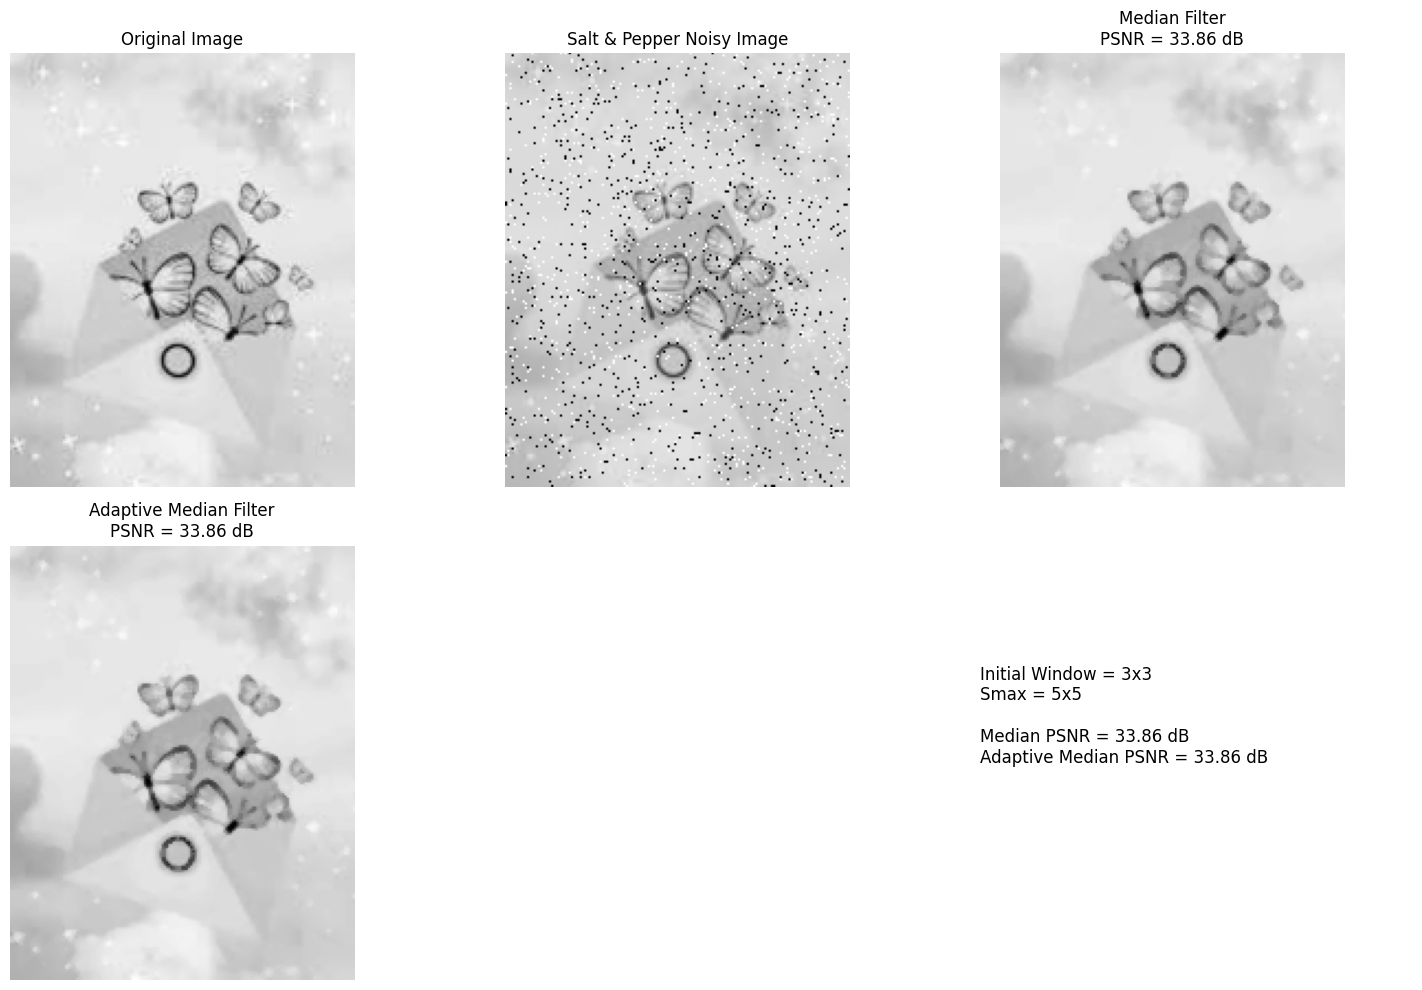

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from math import log10


# ==========================================================
# UPLOAD IMAGE
# ==========================================================

print("Upload the input grayscale image:")
uploaded = files.upload()

filename = next(iter(uploaded))

image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise ValueError("Image could not be loaded.")

print("Image loaded successfully.")
print("Image size:", image.shape)


# ==========================================================
# INPUT WINDOW SIZES
# ==========================================================

Smin = int(input("Enter initial window size (e.g. 3): "))
Smax = int(input("Enter maximum window size (e.g. 7): "))

# Check window sizes
if Smin % 2 == 0 or Smax % 2 == 0:
    raise ValueError("Window sizes must be odd numbers.")

if Smin > Smax:
    raise ValueError("Initial window size must be <= Smax.")


# ==========================================================
# ADD SALT AND PEPPER NOISE
# ==========================================================

# 5% salt-and-pepper noise
noise_amount = 0.05

noisy_image = image.copy()

random = np.random.random(image.shape)

# Salt noise
noisy_image[random < noise_amount / 2] = 255

# Pepper noise
noisy_image[
    (random >= noise_amount / 2) &
    (random < noise_amount)
] = 0


# ==========================================================
# NORMAL MEDIAN FILTER
# ==========================================================

median_filtered = cv2.medianBlur(
    noisy_image,
    Smin
)


# ==========================================================
# ADAPTIVE MEDIAN FILTER
# ==========================================================

def adaptive_median_filter(image, Smin, Smax):

    padded_size = Smax // 2

    padded_image = cv2.copyMakeBorder(
        image,
        padded_size,
        padded_size,
        padded_size,
        padded_size,
        cv2.BORDER_REFLECT
    )

    output = np.zeros_like(image)

    rows, cols = image.shape

    for i in range(rows):
        for j in range(cols):

            window_size = Smin

            while window_size <= Smax:

                half = window_size // 2

                r = i + padded_size
                c = j + padded_size

                window = padded_image[
                    r-half:r+half+1,
                    c-half:c+half+1
                ]

                Zmin = np.min(window)
                Zmax = np.max(window)
                Zmed = np.median(window)
                Zxy = padded_image[r, c]

                # Stage A
                A1 = Zmed - Zmin
                A2 = Zmed - Zmax

                if A1 > 0 and A2 < 0:

                    # Stage B
                    B1 = Zxy - Zmin
                    B2 = Zxy - Zmax

                    if B1 > 0 and B2 < 0:
                        output[i, j] = Zxy
                    else:
                        output[i, j] = Zmed

                    break

                else:
                    window_size += 2

            # If maximum window size is reached
            if window_size > Smax:
                output[i, j] = Zmed

    return output


print("\nApplying Adaptive Median Filter...")
print("This may take some time for a large image.")

adaptive_filtered = adaptive_median_filter(
    noisy_image,
    Smin,
    Smax
)


# ==========================================================
# PSNR CALCULATION
# ==========================================================

def calculate_psnr(original, processed):

    mse = np.mean(
        (original.astype(np.float64) -
         processed.astype(np.float64)) ** 2
    )

    if mse == 0:
        return float("inf")

    psnr = 10 * log10((255 ** 2) / mse)

    return psnr


psnr_noisy = calculate_psnr(image, noisy_image)

psnr_median = calculate_psnr(
    image,
    median_filtered
)

psnr_adaptive = calculate_psnr(
    image,
    adaptive_filtered
)


# ==========================================================
# DISPLAY PSNR
# ==========================================================

print("\n========== PSNR COMPARISON ==========")

print(f"Noisy Image PSNR        : {psnr_noisy:.2f} dB")
print(f"Median Filter PSNR     : {psnr_median:.2f} dB")
print(f"Adaptive Median PSNR   : {psnr_adaptive:.2f} dB")

if psnr_adaptive > psnr_median:
    print("\nAdaptive Median Filter gives better PSNR.")
else:
    print("\nMedian Filter gives better PSNR for this image.")


# ==========================================================
# DISPLAY RESULTS
# ==========================================================

plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(noisy_image, cmap="gray")
plt.title("Salt & Pepper Noisy Image")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(median_filtered, cmap="gray")
plt.title(f"Median Filter\nPSNR = {psnr_median:.2f} dB")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(adaptive_filtered, cmap="gray")
plt.title(f"Adaptive Median Filter\nPSNR = {psnr_adaptive:.2f} dB")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.axis("off")

plt.subplot(2, 3, 6)
plt.text(
    0.1,
    0.5,
    f"Initial Window = {Smin}x{Smin}\n"
    f"Smax = {Smax}x{Smax}\n\n"
    f"Median PSNR = {psnr_median:.2f} dB\n"
    f"Adaptive Median PSNR = {psnr_adaptive:.2f} dB",
    fontsize=12
)
plt.axis("off")

plt.tight_layout()
plt.show()